In [8]:
# %%
#Checking in-situ data for quality control - range, missing values, extreme values

#loading libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#loading datasets
t_max_data1 = pd.read_csv(r"..\Data\Raw\max.csv")
t_min_data1 = pd.read_csv(r"..\Data\Raw\min.csv")
rain_data1 = pd.read_csv(r"..\Data\Raw\rain.csv")
station_data1 = pd.read_excel(r"..\Data\Raw\met_station.xlsx")

station_data = pd.DataFrame()
station_data[['index_no','station_name', 'district', 'lat', 'long', 'elevation']] = station_data1[['Index No.','Station Name', 'District', 'Lat', 'Lon', 'Elev']].copy()

# Standardize index_no to handle float/int mismatches (e.g. 101 vs 101.0)
for df in [t_max_data1, t_min_data1, rain_data1, station_data]:
    df['index_no'] = pd.to_numeric(df['index_no'], errors='coerce').astype('Int64')

station_data

,index_no,station_name,district,lat,long,elevation
0,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352
1,103,Patan_West,Baitadi,29.46714,80.54575,1292
2,104,Dadeldhura,Dadeldhura,29.30135,80.58775,1879
3,105,Mahendra_Nagar_Sundarpur,Kanchanpur,28.95477,80.23049,197
4,107,Darchula_Khalanga,Darchula,29.84496,80.54539,945
...,...,...,...,...,...,...
101,1407,Ilam_Tea_Estate,Ilam,26.90964,87.92308,1208
102,1408,Damak,Jhapa,26.67067,87.70318,119
103,1412,Chandra_Gadhi,Jhapa,26.56389,88.06150,90
104,1416,Kanyam_Tea_Estate,Ilam,26.86806,88.07833,1570


In [9]:
# %%
#Preparing datasets for merge

# 1. Merge Max and Min Temp
insitu_data_merged1 = pd.merge(
    t_max_data1, 
    t_min_data1[['index_no', 'year', 'month', 'day', 'min_temp']], 
    how='outer', 
    on=['index_no', 'year', 'month', 'day']
)

# 2. Merge with Rain
insitu_data_merged2 = pd.merge(
    insitu_data_merged1, 
    rain_data1[['index_no', 'year', 'month', 'day', 'rainfall_sum']], 
    how='outer', 
    on=['index_no', 'year', 'month', 'day']
)

insitu_data_merged2

,gsid,index_no,station,district,year,month,day,max_temp,min_temp,rainfall_sum
0,NaN,102,NaN,NaN,1980,1,1,NaN,NaN,7.5
1,NaN,102,NaN,NaN,1980,1,2,NaN,NaN,2.6
2,NaN,102,NaN,NaN,1980,1,3,NaN,NaN,0.0
3,NaN,102,NaN,NaN,1980,1,4,NaN,NaN,0.0
4,NaN,102,NaN,NaN,1980,1,5,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...
1357961,227.0,1419,Phidim (Panchther),Panchther,2020,12,27,22.0,6.5,0.0
1357962,227.0,1419,Phidim (Panchther),Panchther,2020,12,28,22.0,6.5,0.0
1357963,227.0,1419,Phidim (Panchther),Panchther,2020,12,29,21.2,7.0,0.0
1357964,227.0,1419,Phidim (Panchther),Panchther,2020,12,30,21.5,8.5,0.0


In [10]:
#generating dataframe with index, date and variables
df_insitu_merged = insitu_data_merged2[['index_no','year','month','day','max_temp','min_temp','rainfall_sum']].copy()

# Ensure we don't have rows with missing identifiers after the outer merge
df_insitu_merged = df_insitu_merged.dropna(subset=['index_no', 'year', 'month', 'day'])

df_insitu_merged

,index_no,year,month,day,max_temp,min_temp,rainfall_sum
0,102,1980,1,1,NaN,NaN,7.5
1,102,1980,1,2,NaN,NaN,2.6
2,102,1980,1,3,NaN,NaN,0.0
3,102,1980,1,4,NaN,NaN,0.0
4,102,1980,1,5,NaN,NaN,0.0
...,...,...,...,...,...,...,...
1357961,1419,2020,12,27,22.0,6.5,0.0
1357962,1419,2020,12,28,22.0,6.5,0.0
1357963,1419,2020,12,29,21.2,7.0,0.0
1357964,1419,2020,12,30,21.5,8.5,0.0


In [11]:
#from station_data we add station name and coordinates to the insitu data
df_insitu_final = df_insitu_merged.merge(station_data[['index_no','station_name', 'district', 'lat', 'long', 'elevation']], how='left', on='index_no')
df_insitu_final = df_insitu_final.sort_values(by=['index_no','year','month','day'])

#select rows with na values for latitude and checking corresponding index_no
na_latitude = df_insitu_final[df_insitu_final['lat'].isna()]
na_index_nos = na_latitude['index_no'].unique()
print(na_index_nos)

df_insitu_final = df_insitu_final[~df_insitu_final['index_no'].isin(na_index_nos)]
index_list = df_insitu_final['index_no'].unique()
print(index_list)

df_insitu_final = df_insitu_final[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','max_temp','min_temp','rainfall_sum']]
df_insitu_final

<IntegerArray>
[405]
Length: 1, dtype: Int64
<IntegerArray>
[ 102,  103,  104,  105,  107,  202,  203,  204,  207,  215,
 ...
 1314, 1318, 1319, 1320, 1324, 1407, 1408, 1412, 1416, 1419]
Length: 106, dtype: Int64


,index_no,station_name,district,lat,long,elevation,year,month,day,max_temp,min_temp,rainfall_sum
0,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,1,NaN,NaN,7.5
1,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,2,NaN,NaN,2.6
2,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,3,NaN,NaN,0.0
3,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,4,NaN,NaN,0.0
4,102,Baitadi_Gothapani,Baitadi,29.55744,80.41317,1352.0,1980,1,5,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1357961,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,12,27,22.0,6.5,0.0
1357962,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,12,28,22.0,6.5,0.0
1357963,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,12,29,21.2,7.0,0.0
1357964,1419,Phidim,Panchther,27.14367,87.76560,1157.0,2020,12,30,21.5,8.5,0.0


In [12]:
# %%
#for each station findout the start and end date, with number of observations in form - 
#stationID, rainfall_start, rainfall_end, rainfall_obs, max_temp_start, max_temp_end, max_temp_obs, min_temp_start, min_temp_end, min_temp_obs

# Create empty lists to store results
results = []

for station in index_list:
    # Filter data for current station
    station_data_curr = df_insitu_final[df_insitu_final['index_no'] == station]
    
    # Rainfall data
    rain_data = station_data_curr[station_data_curr['rainfall_sum'].notna()]
    if len(rain_data) > 0:
        rain_start = rain_data[['year', 'month', 'day']].iloc[0]
        rain_end = rain_data[['year', 'month', 'day']].iloc[-1]
        rain_obs = len(rain_data)
    else:
        rain_start = pd.Series({'year': None, 'month': None, 'day': None})
        rain_end = pd.Series({'year': None, 'month': None, 'day': None})
        rain_obs = 0
    
    # Max temperature data
    max_temp_data = station_data_curr[station_data_curr['max_temp'].notna()]
    if len(max_temp_data) > 0:
        max_start = max_temp_data[['year', 'month', 'day']].iloc[0]
        max_end = max_temp_data[['year', 'month', 'day']].iloc[-1]
        max_obs = len(max_temp_data)
    else:
        max_start = pd.Series({'year': None, 'month': None, 'day': None})
        max_end = pd.Series({'year': None, 'month': None, 'day': None})
        max_obs = 0
    
    # Min temperature data
    min_temp_data = station_data_curr[station_data_curr['min_temp'].notna()]
    if len(min_temp_data) > 0:
        min_start = min_temp_data[['year', 'month', 'day']].iloc[0]
        min_end = min_temp_data[['year', 'month', 'day']].iloc[-1]
        min_obs = len(min_temp_data)
    else:
        min_start = pd.Series({'year': None, 'month': None, 'day': None})
        min_end = pd.Series({'year': None, 'month': None, 'day': None})
        min_obs = 0
    
    # Append results to list
    results.append({
        'stationID': station,
        'rainfall_start': f"{rain_start['year']}-{rain_start['month']}-{rain_start['day']}" if rain_start['year'] is not None else None,
        'rainfall_end': f"{rain_end['year']}-{rain_end['month']}-{rain_end['day']}" if rain_end['year'] is not None else None,
        'rainfall_obs': rain_obs,
        'max_temp_start': f"{max_start['year']}-{max_start['month']}-{max_start['day']}" if max_start['year'] is not None else None,
        'max_temp_end': f"{max_end['year']}-{max_end['month']}-{max_end['day']}" if max_end['year'] is not None else None,
        'max_temp_obs': max_obs,
        'min_temp_start': f"{min_start['year']}-{min_start['month']}-{min_start['day']}" if min_start['year'] is not None else None,
        'min_temp_end': f"{min_end['year']}-{min_end['month']}-{min_end['day']}" if min_end['year'] is not None else None,
        'min_temp_obs': min_obs
    })

# Convert results to DataFrame and save to CSV
results_df = pd.DataFrame(results)
results_df.to_csv(r'..\Data\Processed\Insitu\insitu_period_1990_2019.csv', index=False)
print(results_df)

     stationID rainfall_start rainfall_end  rainfall_obs max_temp_start  \
0          102       1980-1-1   2020-12-31         14762      2010-1-24   
1          103       1980-1-1    2020-6-30         14763       1981-1-1   
2          104       1980-1-1   2020-12-31         14976       1980-1-1   
3          105       1980-1-1   2020-12-31         12705       1980-1-1   
4          107       1980-1-1   2019-10-31         14549      1989-5-13   
..         ...            ...          ...           ...            ...   
101       1407       1980-1-1   2020-12-31         13614       1980-1-1   
102       1408       1980-1-1   2020-12-31         14852      2013-5-22   
103       1412       1980-1-1   2020-12-31         14852      2011-7-22   
104       1416       1980-1-1   2020-12-31         14371       1980-1-1   
105       1419       1980-1-1   2020-12-31         14931      1989-3-13   

    max_temp_end  max_temp_obs min_temp_start min_temp_end  min_temp_obs  
0     2020-12-31        

In [13]:
# %%
#checking data avaliability for period 1990-2019 for each station
data_percentage = {}

for station in index_list:
    station_data_curr = df_insitu_final[df_insitu_final['index_no'] == station]
    #exact days from 1990 to 2020
    total_days = pd.date_range(start='1990-01-01', end='2019-12-31', freq='D')
    total_days_count = len(total_days)
    
    #days with data for rainfall
    rain_days = station_data_curr[station_data_curr['rainfall_sum'].notna()].copy()
    rain_days['date'] = pd.to_datetime(rain_days[['year', 'month', 'day']])
    rain_days_count = len(rain_days[rain_days['date'].between('1990-01-01', '2019-12-31')])
    #calculating percentage
    rain_data_percentage = (rain_days_count / total_days_count) * 100
    data_percentage.setdefault(station, {})['rainfall_data_percentage'] = rain_data_percentage
    
    #days with data for max temp
    max_days = station_data_curr[station_data_curr['max_temp'].notna()].copy()
    max_days['date'] = pd.to_datetime(max_days[['year', 'month', 'day']])
    max_days_count = len(max_days[max_days['date'].between('1990-01-01', '2019-12-31')])
    #calculating percentage
    max_data_percentage = (max_days_count / total_days_count) * 100
    data_percentage.setdefault(station, {})['max_temp_data_percentage'] = max_data_percentage
    
    #days with data for min temp
    min_days = station_data_curr[station_data_curr['min_temp'].notna()].copy()
    min_days['date'] = pd.to_datetime(min_days[['year', 'month', 'day']])
    min_days_count = len(min_days[min_days['date'].between('1990-01-01', '2019-12-31')])
    #calculating percentage
    min_data_percentage = (min_days_count / total_days_count) * 100
    data_percentage.setdefault(station, {})['min_temp_data_percentage'] = min_data_percentage

#convert to DataFrame
data_percentage_df = pd.DataFrame.from_dict(data_percentage, orient='index')
data_percentage_df.to_csv(r'..\Data\Processed\Insitu\station_data_percentage_1990_2019.csv')
print(data_percentage_df)

      rainfall_data_percentage  max_temp_data_percentage  \
102                  98.046911                 28.967783   
103                 100.000000                 96.623163   
104                 100.000000                 99.963494   
105                  93.118554                 93.091175   
107                  99.443278                 97.097746   
...                        ...                       ...   
1407                 90.946427                 83.061057   
1408                 99.142101                 21.447476   
1412                 98.886557                 26.850415   
1416                 94.478416                 90.700009   
1419                 99.589304                 97.544948   

      min_temp_data_percentage  
102                  32.107329  
103                  90.773022  
104                  99.561924  
105                  91.274984  
107                  97.928265  
...                        ...  
1407                 81.819841  
1408           

In [14]:
# %%
#print no of statations with >80% data availability for each parameter
rainfall_stations_80 = data_percentage_df[data_percentage_df['rainfall_data_percentage'] > 80]
max_temp_stations_80 = data_percentage_df[data_percentage_df['max_temp_data_percentage'] > 80]
min_temp_stations_80 = data_percentage_df[data_percentage_df['min_temp_data_percentage'] > 80]
print("Stations with >80% Rainfall Data Availability:", len(rainfall_stations_80))
print("Stations with >80% Max Temp Data Availability:", len(max_temp_stations_80))
print("Stations with >80% Min Temp Data Availability:", len(min_temp_stations_80))

Stations with >80% Rainfall Data Availability: 68
Stations with >80% Max Temp Data Availability: 60
Stations with >80% Min Temp Data Availability: 60


In [15]:
# %%
import ee
import geemap
from ipyleaflet import Marker, Icon, MarkerCluster

# Authenticate and initialize
try:
    ee.Initialize(project='ee-jeevankatel3')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='ee-jeevankatel3')

# Create map (ipyleaflet backend)
m = geemap.Map(center=[29.5, 80.4], zoom=8)

# Create clusters for each group
cluster_rain = MarkerCluster(name='Rainfall >80%')
cluster_max = MarkerCluster(name='MaxTemp >80%')
cluster_min = MarkerCluster(name='MinTemp >80%')

# Add rainfall stations (Updated to use lists for efficiency)
rain_markers = []
for station in rainfall_stations_80.index:
    station_info = df_insitu_final[df_insitu_final['index_no'] == station].iloc[0]
    lat = float(station_info['lat'])
    lon = float(station_info['long'])
    name = str(station_info['station_name'])
    icon = Icon(icon_url='https://maps.gstatic.com/mapfiles/ms2/micons/blue-dot.png', icon_size=[24, 24])
    rain_markers.append(Marker(location=(lat, lon), title=name, icon=icon))
cluster_rain.markers = tuple(rain_markers)

# Add max temperature stations
max_markers = []
for station in max_temp_stations_80.index:
    station_info = df_insitu_final[df_insitu_final['index_no'] == station].iloc[0]
    lat = float(station_info['lat'])
    lon = float(station_info['long'])
    name = str(station_info['station_name'])
    icon = Icon(icon_url='https://maps.gstatic.com/mapfiles/ms2/micons/red-dot.png', icon_size=[24, 24])
    max_markers.append(Marker(location=(lat, lon), title=name, icon=icon))
cluster_max.markers = tuple(max_markers)

# Add min temperature stations
min_markers = []
for station in min_temp_stations_80.index:
    station_info = df_insitu_final[df_insitu_final['index_no'] == station].iloc[0]
    lat = float(station_info['lat'])
    lon = float(station_info['long'])
    name = str(station_info['station_name'])
    icon = Icon(icon_url='https://maps.gstatic.com/mapfiles/ms2/micons/green-dot.png', icon_size=[24, 24])
    min_markers.append(Marker(location=(lat, lon), title=name, icon=icon))
cluster_min.markers = tuple(min_markers)

# Add clusters as layers
m.add_layer(cluster_rain)
m.add_layer(cluster_max)
m.add_layer(cluster_min)

# Add layer control
m.add_layer_control()

# Display
m

Map(center=[29.5, 80.4], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

Text(0, 0.5, 'Elevation (m)')

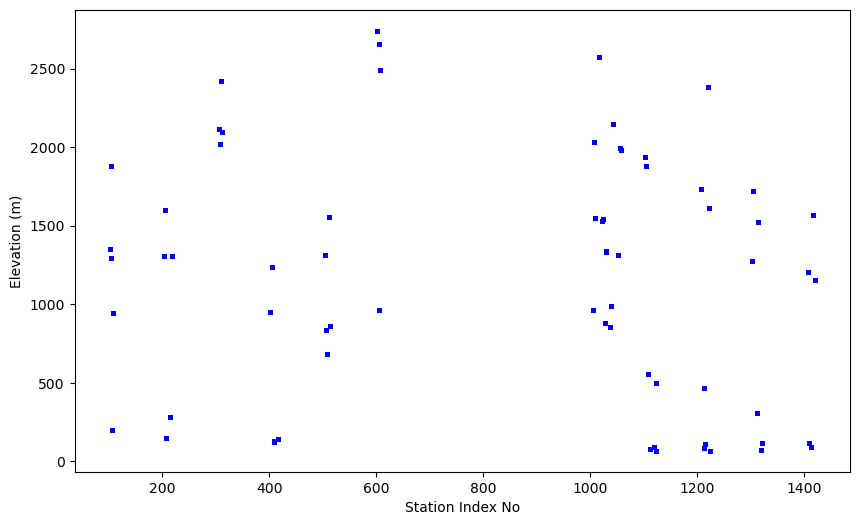

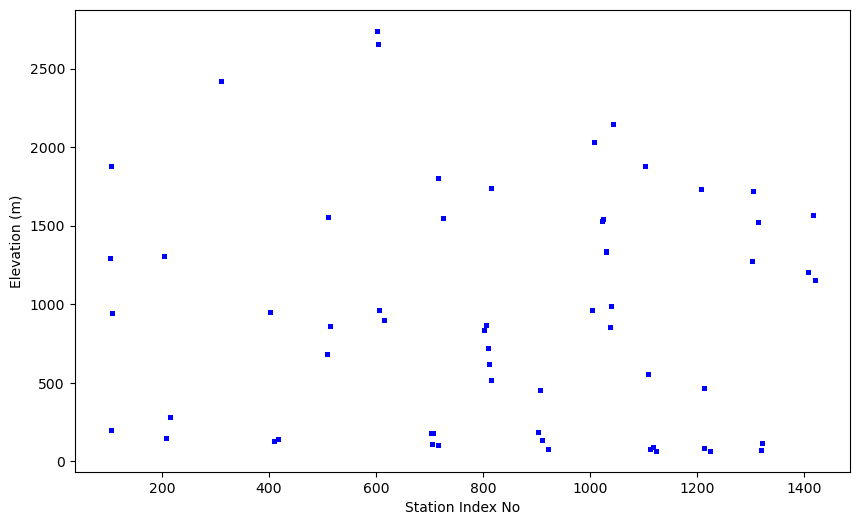

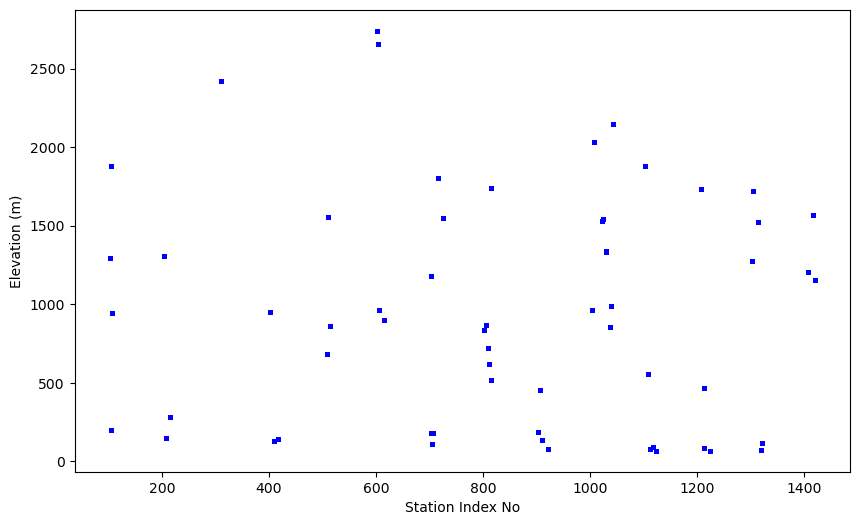

In [16]:
# %%
#get list of stations with >80% data availability
list_tmax_stn = list(max_temp_stations_80.index)
list_tmin_stn = list(min_temp_stations_80.index)
list_rain_stn = list(rainfall_stations_80.index)

#cut original dataframe to include - qualified stations, date from 1990-2019
df_insitu_rainfall = df_insitu_final[
    (df_insitu_final['index_no'].isin(list_rain_stn)) &
    (pd.to_datetime(df_insitu_final[['year', 'month', 'day']]).between('1990-01-01', '2019-12-31'))
]

df_insitu_maxtemp = df_insitu_final[
    (df_insitu_final['index_no'].isin(list_tmax_stn)) &
    (pd.to_datetime(df_insitu_final[['year', 'month', 'day']]).between('1990-01-01', '2019-12-31'))
]

df_insitu_mintemp = df_insitu_final[
    (df_insitu_final['index_no'].isin(list_tmin_stn)) &
    (pd.to_datetime(df_insitu_final[['year', 'month', 'day']]).between('1990-01-01', '2019-12-31'))     
]

#matplotlib to visualize elevation distribution of stations
plt.figure(figsize=(10,6))
plt.scatter(df_insitu_rainfall['index_no'], df_insitu_rainfall['elevation'], s=5, color='blue')
plt.xlabel('Station Index No')
plt.ylabel('Elevation (m)')

plt.figure(figsize=(10,6))
plt.scatter(df_insitu_maxtemp['index_no'], df_insitu_maxtemp['elevation'], s=5, color='blue')
plt.xlabel('Station Index No')
plt.ylabel('Elevation (m)')

plt.figure(figsize=(10,6))
plt.scatter(df_insitu_mintemp['index_no'], df_insitu_mintemp['elevation'], s=5, color='blue')
plt.xlabel('Station Index No')
plt.ylabel('Elevation (m)')

In [17]:
# %%
#creating final dataframes with selected columns
df_insitu_mintemp_final = df_insitu_mintemp[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','min_temp']]
df_insitu_maxtemp_final = df_insitu_maxtemp[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','max_temp']]
df_insitu_rainfall_final = df_insitu_rainfall[['index_no','station_name', 'district', 'lat', 'long', 'elevation','year','month','day','rainfall_sum']]

df_insitu_rainfall_final.to_csv(r'..\Data\Processed\Insitu\insitu_rainfall_1990_2019.csv', index=False)
df_insitu_mintemp_final.to_csv(r'..\Data\Processed\Insitu\insitu_mintemp_1990_2019.csv', index=False)
df_insitu_maxtemp_final.to_csv(r'..\Data\Processed\Insitu\insitu_maxtemp_1990_2019.csv', index=False)